<a href="https://colab.research.google.com/github/mariarango521-oss/proyecto_analitica_financiera/blob/main/04_series_temporales_financieras.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04 · Series temporales financieras

**Financial Analytics Lab · Python · pandas · matplotlib**

**Pregunta orientadora:** ¿cómo cambia nuestra interpretación del rendimiento y del riesgo cuando estudiamos los activos a lo largo del tiempo?

En los módulos anteriores construimos un portafolio, preparamos precios históricos y estudiamos sus distribuciones. Ahora analizaremos el orden temporal de los datos: frecuencias, rezagos, rendimientos acumulados, medias móviles, volatilidad móvil y caídas desde máximos.

**Objetivo:** calcular indicadores verificables, comprender sus representaciones gráficas y elaborar conclusiones financieras que distingan la evidencia histórica de las predicciones.

**Modalidad:** lee las explicaciones, ejecuta el código, resuelve las prácticas y desarrolla el reto integrador. Se requiere conexión a internet para consultar la fuente externa.

## 0 · ¿Qué es una serie temporal?

Una serie temporal es una secuencia de observaciones asociadas a fechas o períodos. Su **orden** importa: el mismo conjunto de rendimientos, colocado en distinto orden, puede producir trayectorias y episodios de riesgo diferentes.

**Índice temporal:** identifica el momento de cada observación. **Frecuencia:** periodicidad (sesiones bursátiles, meses). **Rezago:** observación anterior. **Ventana móvil:** conjunto de observaciones recientes sobre el que se calcula una estadística.

**Reflexiona:** ¿por qué no debemos suponer que todos los días calendario tienen precios bursátiles?

## 1 · Consultar y validar los precios

Recuperaremos MSFT, AAPL y JPM, los mismos activos de los módulos anteriores. Puedes utilizar el archivo `precios_portafolio.csv` generado previamente o realizar una consulta nueva. El rango se registra con fechas explícitas; `end` es exclusivo y `auto_adjust=True` solicita ajustes según la fuente.

In [ ]:
%pip -q install yfinance pandas numpy matplotlib

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
from datetime import datetime, timezone

TICKERS = ["MSFT", "AAPL", "JPM"]
INICIO = "2023-01-01"
FIN = "2025-01-01"
USAR_CSV = False
print("Consulta UTC:", datetime.now(timezone.utc).isoformat(timespec="seconds"))

Consulta UTC: 2026-11-13T02:14:04+00:00


In [ ]:
if USAR_CSV:
    from google.colab import files
    archivos = files.upload()
    if "precios_portafolio.csv" not in archivos:
        raise FileNotFoundError("Sube precios_portafolio.csv del módulo 02.")
    precios = pd.read_csv("precios_portafolio.csv", index_col="Fecha", parse_dates=["Fecha"])
else:
    series = []
    for ticker in TICKERS:
        tabla = yf.download(ticker, start=INICIO, end=FIN,
                            auto_adjust=True, progress=False, multi_level_index=False)
        if tabla.empty or "Close" not in tabla.columns:
            raise RuntimeError(f"No se obtuvieron cierres para {ticker}.")
        series.append(tabla[["Close"]].rename(columns={"Close": ticker}))
    precios = pd.concat(series, axis=1, join="inner")

precios.index = pd.to_datetime(precios.index)
precios = precios.sort_index()
precios = precios.loc[~precios.index.duplicated(keep="first")]
precios = precios.apply(pd.to_numeric, errors="coerce").dropna(how="any")
precios = precios.loc[(precios > 0).all(axis=1)]
if len(precios) < 60:
    raise ValueError("Se necesitan al menos 60 observaciones válidas.")
print("Dimensiones:", precios.shape)
display(precios.head())

Dimensiones: (502, 3)


,MSFT,AAPL,JPM
Date,,,
2023-01-03,232.510544,122.876747,123.120934
2023-01-04,222.339783,124.144127,124.269073
2023-01-05,215.750137,122.827621,124.241516
2023-01-06,218.292862,127.346931,126.618942
2023-01-09,220.418213,127.867683,126.095726


**Interpretación:** cada fila representa una fecha común a los activos. Los días sin negociación no deben completarse con precios ficticios.

**Tu práctica 1:** verifica que el índice sea de fechas, esté ordenado y no contenga duplicados. Explica por qué trabajar con fechas comunes facilita las comparaciones.

In [ ]:
# Verificar índice de fechas
print("Índice de fechas:", isinstance(precios.index, pd.DatetimeIndex))

# Verificar orden cronológico
print("Fechas ordenadas:", precios.index.is_monotonic_increasing)

# Verificar fechas duplicadas
print("Fechas duplicadas:", precios.index.duplicated().sum())

# Mostrar primera y última fecha
print("Primera fecha:", precios.index.min())
print("Última fecha:", precios.index.max())

# Mostrar cantidad de observaciones
print("Número de observaciones:", len(precios))

# Mostrar los datos
display(precios.head())

Índice de fechas: True
Fechas ordenadas: True
Fechas duplicadas: 0
Primera fecha: 2023-01-03 00:00:00
Última fecha: 2024-12-31 00:00:00
Número de observaciones: 502


,MSFT,AAPL,JPM
Date,,,
2023-01-03,232.510544,122.876747,123.120934
2023-01-04,222.339783,124.144127,124.269073
2023-01-05,215.750137,122.827621,124.241516
2023-01-06,218.292862,127.346931,126.618942
2023-01-09,220.418213,127.867683,126.095726


## 2 · Rezagos y rendimientos

`shift(1)` recupera el precio de la observación anterior. El rendimiento simple se define como **r(t) = P(t) / P(t−1) − 1**. `pct_change(fill_method=None)` aplica esa relación a toda la serie.

La observación anterior no siempre corresponde al día calendario anterior: entre sesiones bursátiles pueden existir fines de semana y festivos.

In [ ]:
activo = precios.columns[0]
verificacion = pd.DataFrame({
    "Precio": precios[activo],
    "Precio anterior": precios[activo].shift(1)
})
verificacion["Manual"] = verificacion["Precio"] / verificacion["Precio anterior"] - 1
verificacion["Pandas"] = precios[activo].pct_change(fill_method=None)
display(verificacion.head())
assert np.allclose(verificacion["Manual"].dropna(), verificacion["Pandas"].dropna())
rendimientos = precios.pct_change(fill_method=None).dropna(how="any")
print("Rendimientos contrastados.")

,Precio,Precio anterior,Manual,Pandas
Date,,,,
2023-01-03,232.510544,NaN,NaN,NaN
2023-01-04,222.339783,232.510544,-0.043743,-0.043743
2023-01-05,215.750137,222.339783,-0.029638,-0.029638
2023-01-06,218.292862,215.750137,0.011786,0.011786
2023-01-09,220.418213,218.292862,0.009736,0.009736


Rendimientos contrastados.


El índice debe contener fechas, estar ordenado cronológicamente y no tener duplicados. Trabajar con fechas comunes permite comparar los activos en los mismos periodos y obtener resultados más precisos y confiables.

**Tu práctica 2:** verifica el rendimiento de otro activo con `shift(1)` y explica por qué el primer resultado es faltante.

In [ ]:
activo = "AAPL"

verificacion = pd.DataFrame({
    "Precio": precios[activo],
    "Precio anterior": precios[activo].shift(1)
})

verificacion["Manual"] = (
    verificacion["Precio"] / verificacion["Precio anterior"] - 1
)

verificacion["Pandas"] = precios[activo].pct_change(fill_method=None)

display(verificacion.head())

assert np.allclose(
    verificacion["Manual"].dropna(),
    verificacion["Pandas"].dropna()
)

print("Rendimientos comprobados correctamente.")

,Precio,Precio anterior,Manual,Pandas
Date,,,,
2023-01-03,122.876747,NaN,NaN,NaN
2023-01-04,124.144127,122.876747,0.010314,0.010314
2023-01-05,122.827621,124.144127,-0.010605,-0.010605
2023-01-06,127.346931,122.827621,0.036794,0.036794
2023-01-09,127.867683,127.346931,0.004089,0.004089


Rendimientos comprobados correctamente.


El primer resultado es NaN porque no existe un precio anterior para realizar la comparación. La fórmula manual coincide con Pandas.

## 3 · Frecuencias y cierres mensuales

`resample('ME').last()` selecciona el último precio disponible de cada mes calendario. El rendimiento mensual se calcula comparando **cierres mensuales consecutivos**, no promediando rendimientos diarios. Cambiar la frecuencia modifica la cantidad de observaciones y la escala de interpretación.

In [ ]:
cierres_mensuales = precios.resample("ME").last().dropna(how="any")
rendimientos_mensuales = cierres_mensuales.pct_change(fill_method=None).dropna(how="any")
print("Observaciones originales:", len(precios))
print("Cierres mensuales:", len(cierres_mensuales))
display(cierres_mensuales.head())
display((rendimientos_mensuales * 100).head().round(3))

Observaciones originales: 502
Cierres mensuales: 24


,MSFT,AAPL,JPM
Date,,,
2023-01-31,240.497711,141.759689,128.473160
2023-02-28,242.666489,145.046097,131.584946
2023-03-31,280.493652,162.255630,119.615158
2023-04-30,298.940369,166.958984,127.890190
2023-05-31,320.196747,174.648819,125.549614


,MSFT,AAPL,JPM
Date,,,
2023-02-28,0.902,2.318,2.422
2023-03-31,15.588,11.865,-9.097
2023-04-30,6.577,2.899,6.918
2023-05-31,7.111,4.606,-1.830
2023-06-30,3.700,9.433,7.170


**Tu práctica 3:** comprueba manualmente un rendimiento mensual y explica por qué no equivale al promedio de los rendimientos diarios.

In [ ]:
activo = precios.columns[0]

precio_anterior = cierres_mensuales[activo].iloc[0]
precio_actual = cierres_mensuales[activo].iloc[1]

manual = (precio_actual / precio_anterior) - 1
pandas = rendimientos_mensuales[activo].iloc[0]

print("Rendimiento manual:", manual)
print("Rendimiento pandas:", pandas)

assert np.isclose(manual, pandas)

print("Rendimiento mensual comprobado correctamente.")

Rendimiento manual: 0.009017871542994937
Rendimiento pandas: 0.009017871542994937
Rendimiento mensual comprobado correctamente.


El rendimiento mensual se calcula comparando dos cierres mensuales consecutivos. No equivale al promedio de los rendimientos diarios porque refleja la variación acumulada entre el cierre de un mes y el siguiente.

## 4 · Rendimiento acumulado

El rendimiento acumulado se obtiene multiplicando los factores **(1 + rendimiento)** de cada período y restando uno. En una serie de precios consistente y sin flujos adicionales también equivale a **precio actual / precio inicial − 1**.

**No se calcula sumando rendimientos simples.** El gráfico muestra cómo cambia el valor relativo desde el comienzo del período.

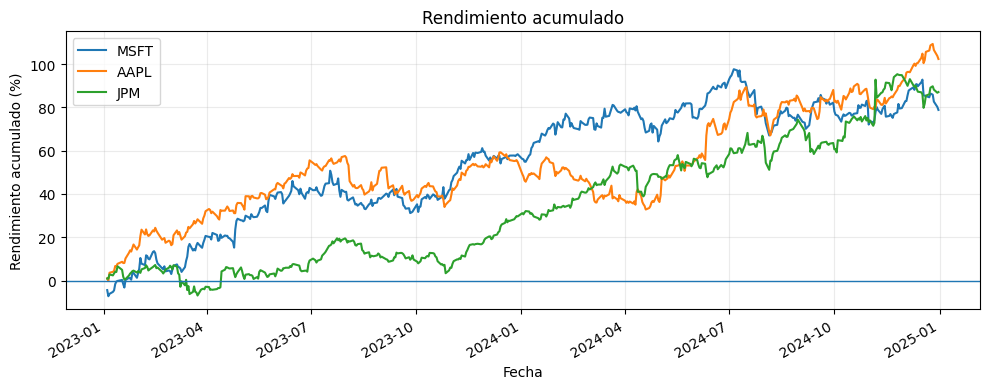

In [ ]:
acumulado = (1 + rendimientos).cumprod() - 1
acumulado_precios = precios.loc[rendimientos.index].div(precios.iloc[0]).sub(1)
assert np.allclose(acumulado.to_numpy(), acumulado_precios.to_numpy(), atol=1e-10)
ax = (acumulado * 100).plot(figsize=(10, 4))
ax.set(title="Rendimiento acumulado", xlabel="Fecha", ylabel="Rendimiento acumulado (%)")
ax.axhline(0, linewidth=1)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Tu práctica 4:** describe un período de caída o recuperación en la curva de un activo. Diferencia el rendimiento acumulado del rendimiento entre dos observaciones.

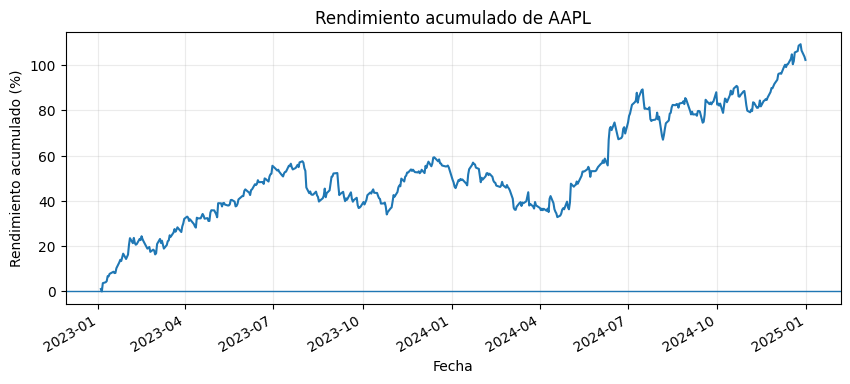

In [ ]:
activo = "AAPL"

ax = (acumulado[activo] * 100).plot(figsize=(10, 4))
ax.set(title=f"Rendimiento acumulado de {activo}",
       xlabel="Fecha", ylabel="Rendimiento acumulado (%)")
ax.axhline(0, linewidth=1)
ax.grid(alpha=0.25)
plt.show()

La trayectoria del activo presenta períodos de caída y recuperación. El rendimiento acumulado permite observar el resultado total desde el inicio de la inversión, mientras que el rendimiento entre dos observaciones refleja únicamente el cambio ocurrido entre esas dos fechas.

## 5 · Medias móviles

Una media móvil de **n observaciones** calcula el promedio de los últimos n precios. Se utiliza para suavizar movimientos de corto plazo. En datos bursátiles, 20 observaciones no equivalen necesariamente a 20 días calendario.

`rolling(window=20, min_periods=20).mean()` requiere 20 precios antes de producir el primer valor. Las medias móviles describen trayectorias pasadas, no predicen precios.

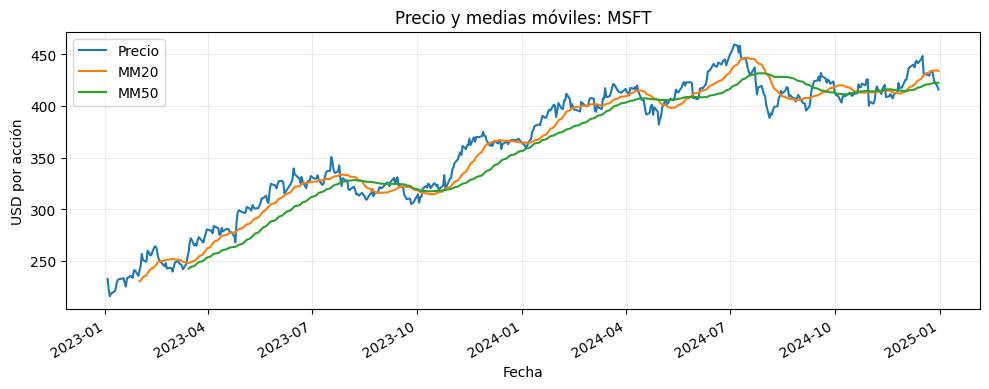

In [ ]:
activo = precios.columns[0]
moviles = pd.DataFrame({"Precio": precios[activo]})
moviles["MM20"] = moviles["Precio"].rolling(20, min_periods=20).mean()
moviles["MM50"] = moviles["Precio"].rolling(50, min_periods=50).mean()
ax = moviles.plot(figsize=(10, 4))
ax.set(title=f"Precio y medias móviles: {activo}", xlabel="Fecha", ylabel="USD por acción")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Tu práctica 5:** incorpora una media móvil de 10 observaciones. ¿Cuál responde más rápido a las fluctuaciones, MM10 o MM50? ¿Por qué hay valores faltantes al inicio?

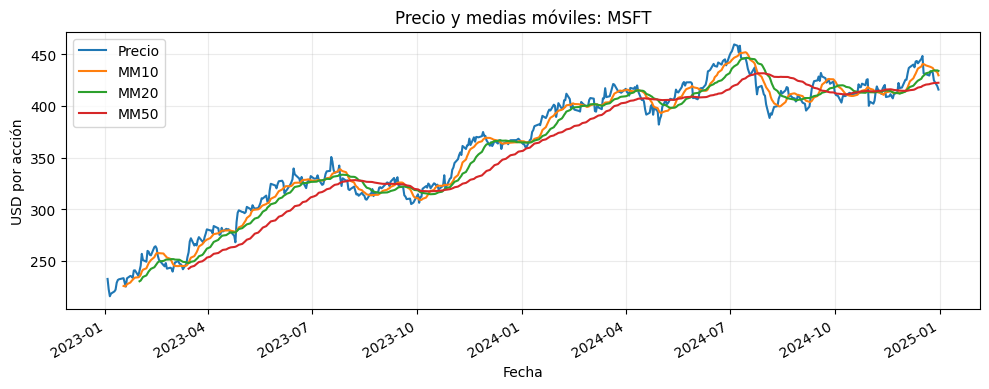

In [ ]:
activo = precios.columns[0]

moviles = pd.DataFrame({"Precio": precios[activo]})
moviles["MM10"] = moviles["Precio"].rolling(10, min_periods=10).mean()
moviles["MM20"] = moviles["Precio"].rolling(20, min_periods=20).mean()
moviles["MM50"] = moviles["Precio"].rolling(50, min_periods=50).mean()

ax = moviles.plot(figsize=(10, 4))
ax.set(title=f"Precio y medias móviles: {activo}",
       xlabel="Fecha", ylabel="USD por acción")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

La MM10 responde más rápido a las fluctuaciones del precio porque utiliza menos observaciones y se adapta con mayor facilidad a los cambios recientes. La MM50 es más lenta y suaviza más las variaciones.

Los valores faltantes al inicio aparecen porque se necesitan 10, 20 o 50 observaciones, respectivamente, para calcular cada media móvil.

## 6 · Volatilidad móvil

La volatilidad histórica móvil se aproxima mediante la **desviación estándar de los rendimientos** dentro de una ventana. `rolling(20).std(ddof=1)` calcula la dispersión muestral de 20 observaciones consecutivas.

Un aumento de la volatilidad indica mayor variabilidad local de rendimientos; no revela por sí solo si el activo subió o bajó. Presentaremos el resultado **en porcentaje por observación**, sin confundirlo con una medida anualizada.

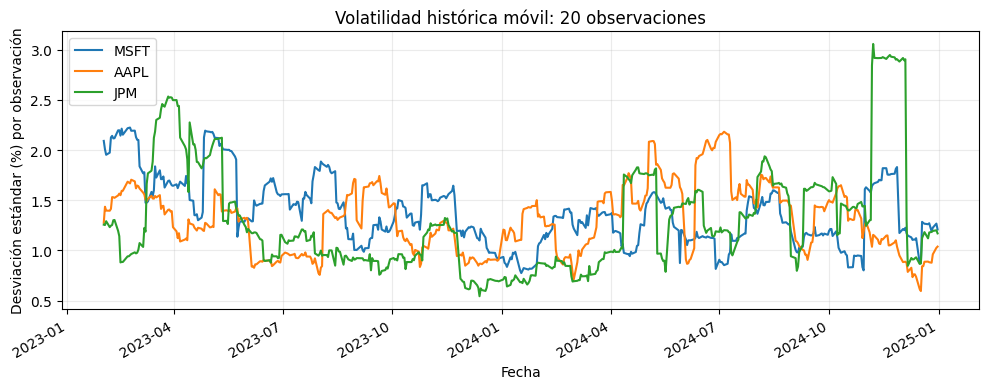

In [ ]:
volatilidad_20 = rendimientos.rolling(20, min_periods=20).std(ddof=1) * 100
ax = volatilidad_20.plot(figsize=(10, 4))
ax.set(title="Volatilidad histórica móvil: 20 observaciones",
       xlabel="Fecha", ylabel="Desviación estándar (%) por observación")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Tu práctica 6:** compara ventanas de 10 y 30 observaciones. Identifica un episodio de variabilidad elevada y explica qué información adicional necesitarías para interpretarlo.

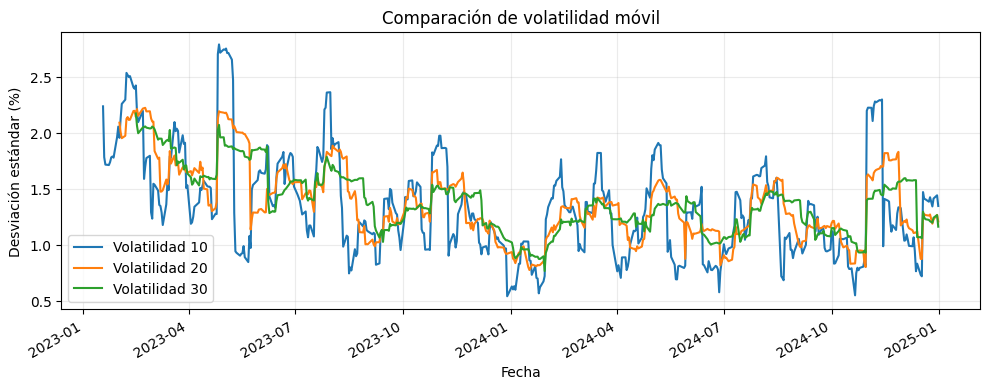

In [ ]:
volatilidad_10 = rendimientos.rolling(10, min_periods=10).std(ddof=1) * 100
volatilidad_20 = rendimientos.rolling(20, min_periods=20).std(ddof=1) * 100
volatilidad_30 = rendimientos.rolling(30, min_periods=30).std(ddof=1) * 100

volatilidades = pd.concat({
    "Volatilidad 10": volatilidad_10.iloc[:, 0],
    "Volatilidad 20": volatilidad_20.iloc[:, 0],
    "Volatilidad 30": volatilidad_30.iloc[:, 0]
}, axis=1)

ax = volatilidades.plot(figsize=(10, 4))
ax.set(title="Comparación de volatilidad móvil",
       xlabel="Fecha", ylabel="Desviación estándar (%)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

La volatilidad de 10 observaciones reacciona más rápido a los cambios, mientras que la de 30 observaciones es más estable y suaviza las fluctuaciones. Un episodio de volatilidad elevada indica mayor variación en los rendimientos. Para interpretarlo necesitaría conocer las noticias económicas, los resultados de la empresa y los acontecimientos del mercado durante ese período.

## 7 · Drawdown: caídas desde máximos

El **drawdown** compara el valor de una inversión con su máximo acumulado previo: **drawdown(t) = valor(t) / máximo_hasta_t − 1**. Sus valores son cero o negativos.

El **máximo drawdown** es la caída más profunda observada durante el período. Este indicador describe la trayectoria de pérdidas desde máximos y complementa, pero no sustituye, la desviación estándar.

,Máximo drawdown (%)
MSFT,-15.49
AAPL,-16.61
JPM,-13.49


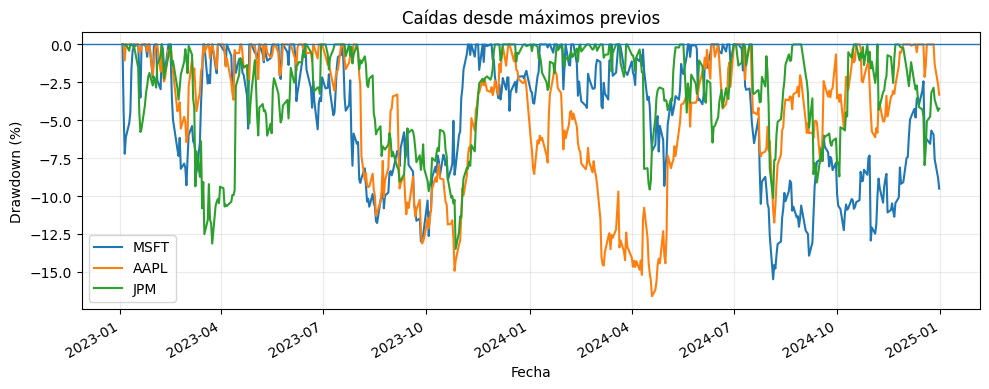

In [ ]:
indice = precios.div(precios.iloc[0])
drawdown = indice.div(indice.cummax()).sub(1)
max_drawdown = drawdown.min() * 100
display(max_drawdown.to_frame("Máximo drawdown (%)").round(2))
ax = (drawdown * 100).plot(figsize=(10, 4))
ax.set(title="Caídas desde máximos previos", xlabel="Fecha", ylabel="Drawdown (%)")
ax.axhline(0, linewidth=1)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
assert (drawdown <= 1e-10).all().all()

**Tu práctica 7:** identifica el activo con el drawdown más profundo. Explica por qué no necesariamente coincide con el de mayor desviación estándar.

In [ ]:
max_drawdown = drawdown.min() * 100
volatilidad_total = rendimientos.std(ddof=1) * 100

comparacion = pd.DataFrame({
    "Máximo drawdown (%)": max_drawdown,
    "Desviación estándar (%)": volatilidad_total
})

display(comparacion.round(2))

print("Activo con mayor caída:", max_drawdown.idxmin())
print("Activo con mayor dispersión:", volatilidad_total.idxmax())

,Máximo drawdown (%),Desviación estándar (%)
MSFT,-15.49,1.43
AAPL,-16.61,1.35
JPM,-13.49,1.40


Activo con mayor caída: AAPL
Activo con mayor dispersión: MSFT


El activo con el drawdown más profundo es el que presenta la mayor caída desde un máximo anterior. No necesariamente coincide con el de mayor desviación estándar, porque el drawdown mide la pérdida acumulada desde un máximo, mientras que la desviación estándar mide la dispersión de los rendimientos. Por eso, un activo puede tener fluctuaciones frecuentes, pero no presentar la caída acumulada más fuerte.

## 8 · Síntesis: comparar sin confundir indicadores

El rendimiento acumulado describe el cambio de valor; las medias móviles suavizan la trayectoria; la volatilidad móvil representa dispersión reciente; el drawdown muestra caídas respecto de máximos previos.

**Interpretación rigurosa:** no existe un indicador único que determine la mejor inversión. Las conclusiones deben señalar período, fuente, supuestos y limitaciones.

In [ ]:
resumen = pd.DataFrame({
    "Rendimiento acumulado (%)": acumulado.iloc[-1] * 100,
    "Volatilidad por observación (%)": rendimientos.std(ddof=1) * 100,
    "Máximo drawdown (%)": max_drawdown,
    "Precio inicial": precios.iloc[0],
    "Precio final": precios.iloc[-1]
})
display(resumen.round(3))
resumen.to_csv("resumen_series_temporales.csv", index_label="Ticker")
print("Exportado: resumen_series_temporales.csv")

,Rendimiento acumulado (%),Volatilidad por observación (%),Máximo drawdown (%),Precio inicial,Precio final
MSFT,78.820,1.429,-15.487,232.511,415.776
AAPL,102.329,1.345,-16.607,122.877,248.616
JPM,87.056,1.396,-13.487,123.121,230.305


Exportado: resumen_series_temporales.csv


**Tu práctica 8:** compara dos activos mediante tres indicadores y redacta una conclusión de 120 a 160 palabras que distinga resultados históricos de expectativas futuras.

In [ ]:
indicadores = resumen[
    ["Rendimiento acumulado (%)",
     "Volatilidad por observación (%)",
     "Máximo drawdown (%)"]
]

display(indicadores.round(3))

,Rendimiento acumulado (%),Volatilidad por observación (%),Máximo drawdown (%)
MSFT,78.820,1.429,-15.487
AAPL,102.329,1.345,-16.607
JPM,87.056,1.396,-13.487


El análisis permite comparar el comportamiento histórico de los dos activos mediante tres indicadores: rendimiento acumulado, volatilidad y máximo drawdown. El rendimiento acumulado muestra cuál obtuvo el mejor resultado durante el período analizado. La volatilidad permite identificar cuál presentó mayores fluctuaciones en sus rendimientos, mientras que el máximo drawdown evidencia cuál experimentó la caída más profunda desde un máximo anterior. En conjunto, estos indicadores ayudan a evaluar la relación entre rentabilidad y riesgo. Un activo puede ofrecer un mayor rendimiento, pero también presentar más volatilidad o pérdidas acumuladas más pronunciadas. Es importante tener en cuenta que estos resultados corresponden únicamente al período estudiado y no garantizan el mismo comportamiento en el futuro. Las decisiones de inversión deben considerar otros factores, como las condiciones del mercado, la situación económica y el perfil de riesgo del inversionista.

## 9 · Reto integrador: informe de series temporales

Elabora un análisis original de **tres activos** con:

1. Pregunta financiera, tickers, fuente y período.
2. Validación del índice temporal y de fechas comunes.
3. Rendimientos simples con comprobación manual.
4. Cierres mensuales y verificación de un rendimiento mensual.
5. Rendimiento acumulado y gráfico interpretado.
6. Medias móviles de 20 y 50 observaciones.
7. Volatilidad móvil de 20 observaciones y comparación temporal.
8. Drawdown y máximo drawdown.
9. Tabla de indicadores exportada a CSV.
10. Conclusión de **200 a 300 palabras**, con hallazgos, supuestos y limitaciones.

**Evidencia:** notebook reproducible con explicaciones, cálculos verificados, gráficos rotulados y fuentes. Reconoce cualquier apoyo de herramientas de IA.

Activos: ['MSFT', 'AAPL', 'JPM']
Fuente: Yahoo Finance
Período solicitado: 2024-01-01 a 2025-01-01
Primera fecha común: 2024-01-02 00:00:00
Última fecha común: 2024-12-31 00:00:00
Observaciones comunes: 252
Índice de fechas: True
Fechas ordenadas: True
Fechas duplicadas: 0
Valores faltantes: 0


,MSFT,AAPL,JPM
Date,,,
2024-01-02,363.117950,183.264740,161.472733
2024-01-03,362.853577,181.892563,160.768967
2024-01-04,360.249176,179.582489,161.835815
2024-01-05,360.063141,178.861816,162.647781
2024-01-08,366.858124,183.185760,162.411758


,Precio,Precio anterior,Manual,Pandas
Date,,,,
2024-01-02,183.264740,NaN,NaN,NaN
2024-01-03,181.892563,183.264740,-0.007487,-0.007487
2024-01-04,179.582489,181.892563,-0.012700,-0.012700
2024-01-05,178.861816,179.582489,-0.004013,-0.004013
2024-01-08,183.185760,178.861816,0.024175,0.024175


Rendimientos comprobados correctamente.
Rendimiento mensual manual: -0.018543171145127824
Rendimiento mensual Pandas: -0.018543171145127824


,MSFT,AAPL,JPM
Date,,,
2024-01-31,389.269562,182.040619,164.621063
2024-02-29,405.742889,178.665009,175.667572
2024-03-31,412.687683,169.501923,189.112167
2024-04-30,381.897003,168.365250,182.086258
2024-05-31,407.938873,190.290100,192.427979


,MSFT,AAPL,JPM
Date,,,
2024-02-29,4.232,-1.854,6.710
2024-03-31,1.712,-5.129,7.653
2024-04-30,-7.461,-0.671,-3.715
2024-05-31,6.819,13.022,5.680
2024-06-30,7.665,9.555,-0.183


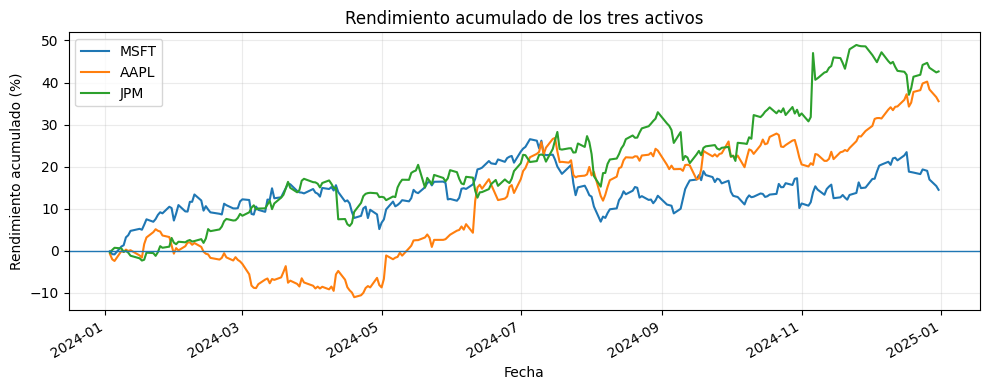

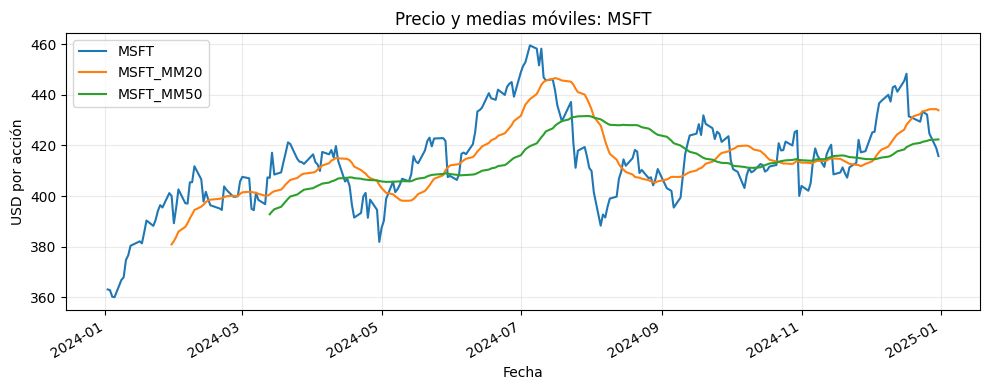

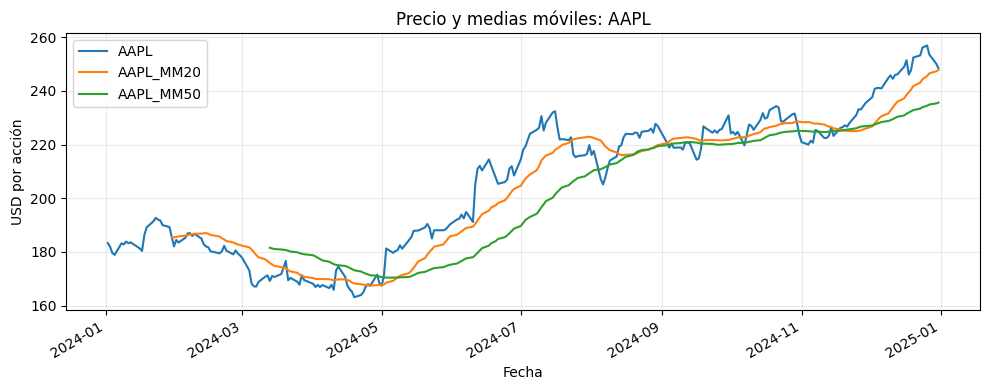

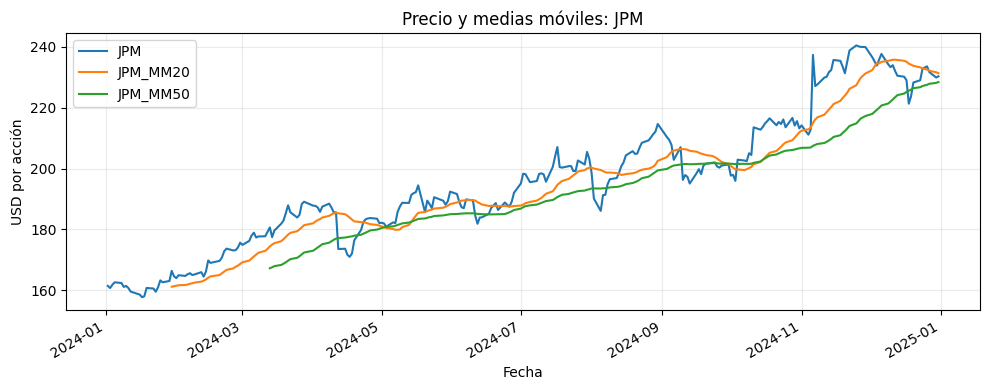

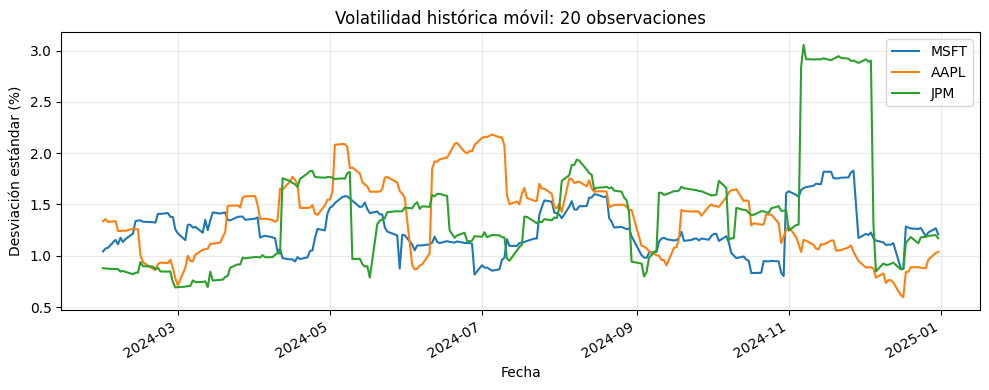

,Máximo drawdown (%)
MSFT,-15.49
AAPL,-15.35
JPM,-10.13


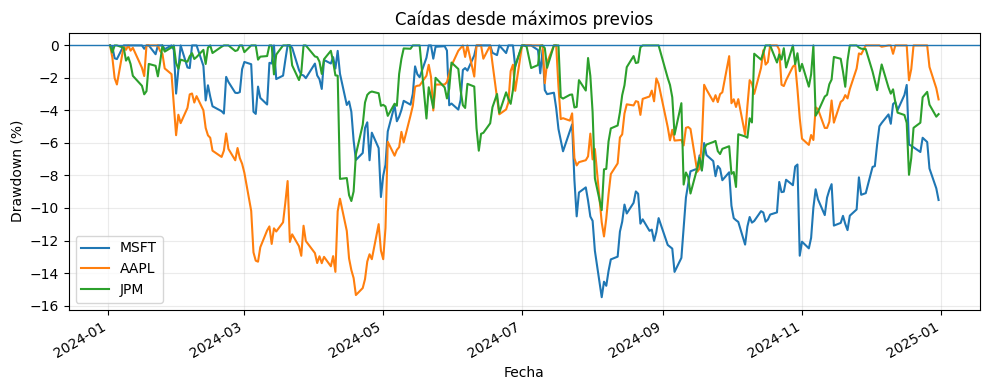

,Rendimiento acumulado (%),Volatilidad por observación (%),Máximo drawdown (%),Precio inicial,Precio final
MSFT,14.502,1.257,-15.487,363.118,415.776
AAPL,35.556,1.412,-15.355,183.265,248.427
JPM,42.628,1.482,-10.130,161.473,230.305


Exportado: resumen_series_temporales.csv
Mayor rendimiento acumulado: JPM
Mayor volatilidad: JPM
Drawdown más profundo: MSFT


In [ ]:

# 1. IMPORTAR LIBRERÍAS Y DESCARGAR DATOS

import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

TICKERS = ["MSFT", "AAPL", "JPM"]
INICIO = "2024-01-01"
FIN = "2025-01-01"

series = []

for ticker in TICKERS:
    tabla = yf.download(
        ticker,
        start=INICIO,
        end=FIN,
        auto_adjust=True,
        progress=False,
        multi_level_index=False
    )

    if tabla.empty or "Close" not in tabla.columns:
        raise RuntimeError(f"No se obtuvieron datos para {ticker}.")

    series.append(tabla[["Close"]].rename(columns={"Close": ticker}))

# Unir las tres series usando únicamente fechas comunes
precios = pd.concat(series, axis=1, join="inner")

precios.index = pd.to_datetime(precios.index)
precios = precios.sort_index()
precios = precios.loc[~precios.index.duplicated(keep="first")]
precios = precios.apply(pd.to_numeric, errors="coerce").dropna()
precios = precios.loc[(precios > 0).all(axis=1)]

print("Activos:", TICKERS)
print("Fuente: Yahoo Finance")
print("Período solicitado:", INICIO, "a", FIN)
print("Primera fecha común:", precios.index.min())
print("Última fecha común:", precios.index.max())
print("Observaciones comunes:", len(precios))


# 2. VALIDACIÓN DEL ÍNDICE TEMPORAL

print("Índice de fechas:", isinstance(precios.index, pd.DatetimeIndex))
print("Fechas ordenadas:", precios.index.is_monotonic_increasing)
print("Fechas duplicadas:", precios.index.duplicated().sum())
print("Valores faltantes:", precios.isna().sum().sum())

display(precios.head())


# 3. RENDIMIENTOS SIMPLES Y COMPROBACIÓN MANUAL

rendimientos = precios.pct_change(fill_method=None).dropna()

activo = "AAPL"

verificacion = pd.DataFrame({
    "Precio": precios[activo],
    "Precio anterior": precios[activo].shift(1)
})

verificacion["Manual"] = (
    verificacion["Precio"] / verificacion["Precio anterior"] - 1
)

verificacion["Pandas"] = precios[activo].pct_change(fill_method=None)

display(verificacion.head())

assert np.allclose(
    verificacion["Manual"].dropna(),
    verificacion["Pandas"].dropna()
)

print("Rendimientos comprobados correctamente.")


# 4. CIERRES Y RENDIMIENTOS MENSUALES

cierres_mensuales = precios.resample("ME").last().dropna(how="any")

rendimientos_mensuales = (
    cierres_mensuales.pct_change(fill_method=None).dropna(how="any")
)

activo = "AAPL"

manual = (
    cierres_mensuales[activo].iloc[1] /
    cierres_mensuales[activo].iloc[0] - 1
)

pandas_mensual = rendimientos_mensuales[activo].iloc[0]

print("Rendimiento mensual manual:", manual)
print("Rendimiento mensual Pandas:", pandas_mensual)

assert np.isclose(manual, pandas_mensual)

display(cierres_mensuales.head())
display((rendimientos_mensuales * 100).head().round(3))


# 5. RENDIMIENTO ACUMULADO

acumulado = (1 + rendimientos).cumprod() - 1

acumulado_precios = (
    precios.loc[rendimientos.index]
    .div(precios.iloc[0])
    .sub(1)
)

assert np.allclose(
    acumulado.to_numpy(),
    acumulado_precios.to_numpy(),
    atol=1e-10
)

ax = (acumulado * 100).plot(figsize=(10, 4))
ax.set(
    title="Rendimiento acumulado de los tres activos",
    xlabel="Fecha",
    ylabel="Rendimiento acumulado (%)"
)
ax.axhline(0, linewidth=1)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# 6. MEDIAS MÓVILES DE 20 Y 50 OBSERVACIONES

moviles = precios.copy()

for ticker in TICKERS:
    moviles[f"{ticker}_MM20"] = precios[ticker].rolling(
        20, min_periods=20
    ).mean()

    moviles[f"{ticker}_MM50"] = precios[ticker].rolling(
        50, min_periods=50
    ).mean()

for ticker in TICKERS:
    ax = moviles[[ticker, f"{ticker}_MM20",
                  f"{ticker}_MM50"]].plot(figsize=(10, 4))

    ax.set(
        title=f"Precio y medias móviles: {ticker}",
        xlabel="Fecha",
        ylabel="USD por acción"
    )
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()


# 7. VOLATILIDAD MÓVIL DE 20 OBSERVACIONES

volatilidad_20 = rendimientos.rolling(
    20, min_periods=20
).std(ddof=1) * 100

ax = volatilidad_20.plot(figsize=(10, 4))
ax.set(
    title="Volatilidad histórica móvil: 20 observaciones",
    xlabel="Fecha",
    ylabel="Desviación estándar (%)"
)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# 8. DRAWDOWN Y MÁXIMO DRAWDOWN

indice = precios.div(precios.iloc[0])
drawdown = indice.div(indice.cummax()).sub(1)

max_drawdown = drawdown.min() * 100

display(max_drawdown.to_frame("Máximo drawdown (%)").round(2))

ax = (drawdown * 100).plot(figsize=(10, 4))
ax.set(
    title="Caídas desde máximos previos",
    xlabel="Fecha",
    ylabel="Drawdown (%)"
)
ax.axhline(0, linewidth=1)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

assert (drawdown <= 1e-10).all().all()


# 9. TABLA DE INDICADORES Y EXPORTACIÓN CSV

resumen = pd.DataFrame({
    "Rendimiento acumulado (%)": acumulado.iloc[-1] * 100,
    "Volatilidad por observación (%)": rendimientos.std(ddof=1) * 100,
    "Máximo drawdown (%)": max_drawdown,
    "Precio inicial": precios.iloc[0],
    "Precio final": precios.iloc[-1]
})

display(resumen.round(3))

resumen.to_csv("resumen_series_temporales.csv",
               index_label="Ticker")

print("Exportado: resumen_series_temporales.csv")


# 10. IDENTIFICAR LOS RESULTADOS PRINCIPALES

print("Mayor rendimiento acumulado:",
      resumen["Rendimiento acumulado (%)"].idxmax())

print("Mayor volatilidad:",
      resumen["Volatilidad por observación (%)"].idxmax())

print("Drawdown más profundo:",
      resumen["Máximo drawdown (%)"].idxmin())


## 10 · Autoevaluación y continuidad

- [ ] Comprendo el índice temporal y las frecuencias.
- [ ] Calculo rezagos y rendimientos correctamente.
- [ ] Distingo rendimientos mensuales de diarios.
- [ ] Interpreto el rendimiento acumulado.
- [ ] Comprendo medias y volatilidades móviles.
- [ ] Calculo e interpreto drawdown.
- [ ] Presento conclusiones con límites explícitos.

**Próximo módulo:** relaciones entre activos, correlación, covarianza, regresión y simulación de escenarios.

**Referencias:** [pandas: series temporales](https://pandas.pydata.org/docs/user_guide/timeseries.html) · [pandas: ventanas](https://pandas.pydata.org/docs/user_guide/window.html) · [yfinance](https://ranaroussi.github.io/yfinance/) · [matplotlib](https://matplotlib.org/stable/).

Los resultados históricos no son recomendaciones de inversión.

## Quiz de cierre · Series temporales

**Quiz evaluativo 4 de 4 · componente de quices (15 % total)**

Responde individualmente las cinco preguntas. Las respuestas deben ser originales, razonadas y coherentes con el código que ejecutes. No basta con escribir una definición: explica el significado de los resultados cuando se solicite.

**Criterio sugerido:** cada pregunta vale 1 punto (5 puntos en total). Las preguntas 1–2 evalúan comprensión, 3–4 interpretación y 5 aplicación. La docente verificará las respuestas y registrará la nota conforme a la ponderación institucional de cada quiz.

### Pregunta 1 · Comprensión

¿Qué convierte a un conjunto de observaciones en una serie temporal?

Que las observaciones estén registradas en diferentes momentos del tiempo y ordenadas cronológicamente, permitiendo analizar su evolución y comportamiento.

### Pregunta 2 · Comprensión

Distingue tendencia, estacionalidad y variaciones aleatorias en una serie financiera.

Tendencia: dirección general del comportamiento de los precios a largo plazo (subida o bajada).
Estacionalidad: patrones que se repiten en períodos específicos de tiempo.
Variaciones aleatorias: cambios impredecibles causados por noticias, eventos o condiciones del mercado.

### Pregunta 3 · Interpretación

¿Qué representa una media móvil de 20 observaciones y qué información puede ocultar?

Representa el promedio de los últimos 20 precios, permitiendo identificar tendencias y suavizar fluctuaciones. Puede ocultar cambios bruscos o movimientos recientes del mercado al reducir las variaciones de corto plazo.

### Pregunta 4 · Interpretación

¿Por qué no es equivalente sumar rendimientos diarios a calcular un rendimiento acumulado compuesto?

Porque los rendimientos diarios deben multiplicarse de forma compuesta para reflejar correctamente el efecto de las ganancias y pérdidas acumuladas. Sumarlos puede generar un resultado incorrecto, ya que no considera que cada rendimiento se aplica sobre el capital actualizado.

### Pregunta 5 · Aplicación

Crea una serie de seis precios con fechas y calcula una media móvil de tres observaciones; interpreta el último resultado.

**Tu respuesta:**

_Escribe aquí tu explicación. Si se solicita código, utiliza la celda de Python siguiente._



In [ ]:
import pandas as pd

datos = pd.Series(
    [100, 105, 110, 108, 115, 120],
    index=pd.date_range("2026-01-01", periods=6, freq="D")
)

media_movil = datos.rolling(3).mean()

resultado = pd.DataFrame({
    "Precio": datos,
    "Media móvil 3": media_movil
})

display(resultado)


,Precio,Media móvil 3
2026-01-01,100,NaN
2026-01-02,105,NaN
2026-01-03,110,105.000000
2026-01-04,108,107.666667
2026-01-05,115,111.000000
2026-01-06,120,114.333333
